<a href="https://colab.research.google.com/github/kianahmurao/BMEN600-Group-20/blob/main/BMEN600_(Oct%2015)_MidtermProposal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from scipy.signal import welch

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [37]:
!pip install -q gdown
import os, gdown

FOLDER_ID = '1EikHkFk74B1pN_y6VzKlgm2qAeE0qk4_'
DATA_DIR = 'data'

if not os.path.exists(DATA_DIR):
    gdown.download_folder(id=FOLDER_ID, output=DATA_DIR, quiet=True)

df_ptdemo = pd.read_csv(os.path.join(DATA_DIR, 'file_list.csv'))

group           Healthy  Parkinson's
N                  79.0        276.0
% male             36.7         70.7
% female           63.3         29.3
% right-handed     88.6         94.6
% left-handed      11.4          5.4


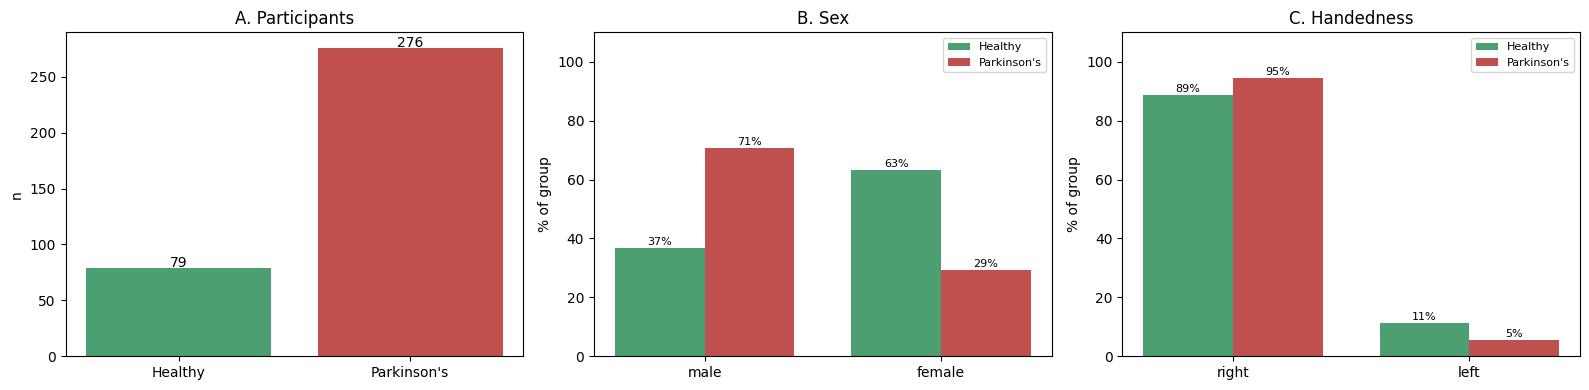

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join(DATA_DIR, 'file_list.csv'))

# keep only healthy (0) and PD (1); drops any other label values (such as 2 for DDx)
df = df[df["label"].isin([0, 1])].copy()
df["group"] = df["label"].map({0: "Healthy", 1: "Parkinson's"})

# Organize text columns so matching is exact to the column in main csv
df["gender"] = df["gender"].str.strip().str.lower()
df["handedness"] = df["handedness"].str.strip().str.lower()



order = ["Healthy", "Parkinson's"]
colors = {"Healthy": "#4C9F70", "Parkinson's": "#C0504D"}

# Creating the summary table that takes the counts of the Healthy and PD groups, turns them into a %
counts = df["group"].value_counts().reindex(order)
pct = lambda col, val: (df[col].eq(val).groupby(df["group"]).mean() * 100).reindex(order)
summary = pd.DataFrame({
    "N": counts,
    "% male": pct("gender", "male"),
    "% female": pct("gender", "female"),
    "% right-handed": pct("handedness", "right"),
    "% left-handed": pct("handedness", "left"),

}).round(1)
print(summary.T)

# Creating a figure that includes subplots for each of the group characteristics
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].bar(order, counts.values, color=[colors[g] for g in order])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 1, str(v), ha="center")
ax[0].set_title("A. Participants"); ax[0].set_ylabel("n")

def grouped(a, cats, title):
    w = 0.38
    for i, g in enumerate(order):
        vals = [pct(c, v).loc[g] for c, v in cats]
        pos = np.arange(len(cats)) + (i - 0.5) * w
        a.bar(pos, vals, w, color=colors[g], label=g)
        for p, v in zip(pos, vals):
            a.text(p, v + 1, f"{v:.0f}%", ha="center", fontsize=8)
    a.set_xticks(range(len(cats))); a.set_xticklabels([v for _, v in cats])
    a.set_ylim(0, 110); a.set_ylabel("% of group"); a.set_title(title); a.legend(fontsize=8)

grouped(ax[1], [("gender", "male"), ("gender", "female")], "B. Sex")
grouped(ax[2], [("handedness", "right"), ("handedness", "left")], "C. Handedness")



fig.tight_layout(); plt.savefig("summary_figure.png", dpi=200); plt.show()

In [39]:
import matplotlib
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


In [40]:
   %matplotlib inline

Creating Healthy Baseline

In [41]:

cols = ['acc x', 'acc y', 'acc z', 'gyr x', 'gyr y', 'gyr z']

def load(filename):
    return pd.read_csv(os.path.join(DATA_DIR, filename),
                       sep=',', header=None, names=cols)

# Healthy participant (046) - r and l correspond to handedness
pt46_relr = load('046_Relaxed_RightWrist.txt')
pt46_rell = load('046_Relaxed_LeftWrist.txt')

pt46_strr = load('046_StretchHold_RightWrist.txt')
pt46_strl = load('046_StretchHold_LeftWrist.txt')

pt46_drr  = load('046_DrinkGlas_RightWrist.txt')
pt46_drl  = load('046_DrinkGlas_LeftWrist.txt')

pt46_holr = load('046_HoldWeight_RightWrist.txt')
pt46_holl = load('046_HoldWeight_LeftWrist.txt')

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch
from scipy.integrate import trapezoid


# Addressing the sampling rate at 100Hz necessary for later steps
FS = 100
#This create a dictionary of key,val pairs to hold the task and dataframes
recordings = {
    ("Relaxed", "right"): pt46_relr,  ("Relaxed", "left"): pt46_rell,
    ("StretchHold", "right"): pt46_strr, ("StretchHold", "left"): pt46_strl,
    ("HoldWeight", "right"): pt46_holr, ("HoldWeight", "left"): pt46_holl,
    ("DrinkGlass", "right"): pt46_drr,  ("DrinkGlass", "left"): pt46_drl,
}
cols = ["acc x", "acc y", "acc z", "gyr x", "gyr y", "gyr z"]
for k, v in recordings.items():
    print(k, v.shape)          # expect ~1024 rows (2048 for Relaxed) x 6

('Relaxed', 'right') (2048, 6)
('Relaxed', 'left') (2048, 6)
('StretchHold', 'right') (1024, 6)
('StretchHold', 'left') (1024, 6)
('HoldWeight', 'right') (1024, 6)
('HoldWeight', 'left') (1024, 6)
('DrinkGlass', 'right') (1024, 6)
('DrinkGlass', 'left') (1024, 6)


In [43]:
#This builds a bandpass filter of 0.5-20Hz
sos = butter(4, [0.5, 20], btype="bandpass", fs=FS, output="sos")

def clean(df):
    x = df[cols].to_numpy(float)[50:]              # drop first 0.5 s (start vibration)
    for j in range(x.shape[1]):                    # fill any short NaN gaps
        bad = np.isnan(x[:, j])
        if bad.any():
            x[bad, j] = np.interp(np.flatnonzero(bad), np.flatnonzero(~bad), x[~bad, j])
    x = sosfiltfilt(sos, x, axis=0)                # applying 0.5-20 Hz filter to all axes
    # the 20 s recordings (Relaxed) are split into two halves
    return np.array_split(x, 2) if len(x) / FS > 15 else [x]

segments = {k: clean(v) for k, v in recordings.items()}
print({k: [len(s) for s in v] for k, v in segments.items()})

{('Relaxed', 'right'): [999, 999], ('Relaxed', 'left'): [999, 999], ('StretchHold', 'right'): [974], ('StretchHold', 'left'): [974], ('HoldWeight', 'right'): [974], ('HoldWeight', 'left'): [974], ('DrinkGlass', 'right'): [974], ('DrinkGlass', 'left'): [974]}


In [44]:
# The function below computes accelerometer and gyrocope features for one segment per sensor
def sensor_features(seg, p):
    f, P = welch(seg, fs=FS, nperseg=256, axis=0)   #welch creates the powers spectral density
    Pt = P.sum(axis=1)                              # sum over x, y, z (acc and gyr independently)
    def logbp(lo, hi):  #this is a bandpower helper by defining frequency bins
        m = (f >= lo) & (f < hi)
        return np.log10(trapezoid(Pt[m], f[m]) + 1e-12)
    pk = (f >= 3) & (f <= 12)
    w = (f >= 0.5) & (f <= 20)
    pn = Pt[w] / Pt[w].sum()
    return {f"{p}_rms": np.log10(np.sqrt(np.mean(np.sum(seg**2, axis=1))) + 1e-12), #root mean squares
            f"{p}_bp_0.5-3": logbp(0.5, 3),         #first frequency bin
            f"{p}_bp_4-6": logbp(4, 6),             # classic parkinsonian tremor frequency band
            f"{p}_bp_6-12": logbp(6, 12),           #next frequency bin
            f"{p}_peak_freq": f[pk][np.argmax(Pt[pk])],  #peak frequency
            f"{p}_spec_entropy": -(pn * np.log(pn + 1e-12)).sum() / np.log(w.sum())} #spectral entropy

rows = {}
for key, segs in segments.items():
    per_seg = [{**sensor_features(s[:, :3], "acc"), **sensor_features(s[:, 3:], "gyr")} for s in segs]
    rows[key] = pd.DataFrame(per_seg).mean()        # average the halves if there are two

signature = pd.DataFrame(rows).T
signature.index.names = ["task", "wrist"]
print(signature.round(2).T)
signature.to_csv("pt46_signature.csv")

task             Relaxed       StretchHold        HoldWeight       DrinkGlass  \
wrist              right  left       right   left      right  left      right   
acc_rms            -2.05 -2.02       -2.15  -2.10      -2.09 -1.80      -0.84   
acc_bp_0.5-3       -5.21 -5.53       -4.61  -4.72      -4.90 -4.53      -1.73   
acc_bp_4-6         -4.81 -4.98       -5.44  -5.35      -5.37 -4.76      -2.78   
acc_bp_6-12        -4.70 -4.36       -5.08  -4.87      -4.56 -4.33      -2.74   
acc_peak_freq       7.62  8.20        4.30   3.12       8.20  5.47       3.12   
acc_spec_entropy    0.81  0.80        0.82   0.90       0.91  0.89       0.66   
gyr_rms            -1.59 -1.51       -1.77  -1.69      -1.54 -1.14      -0.18   
gyr_bp_0.5-3       -3.90 -3.91       -3.95  -3.92      -3.73 -3.35      -0.56   
gyr_bp_4-6         -3.93 -3.98       -4.61  -4.56      -3.89 -3.20      -1.69   
gyr_bp_6-12        -3.94 -3.49       -4.04  -3.89      -3.51 -3.38      -1.73   
gyr_peak_freq       6.25  6.

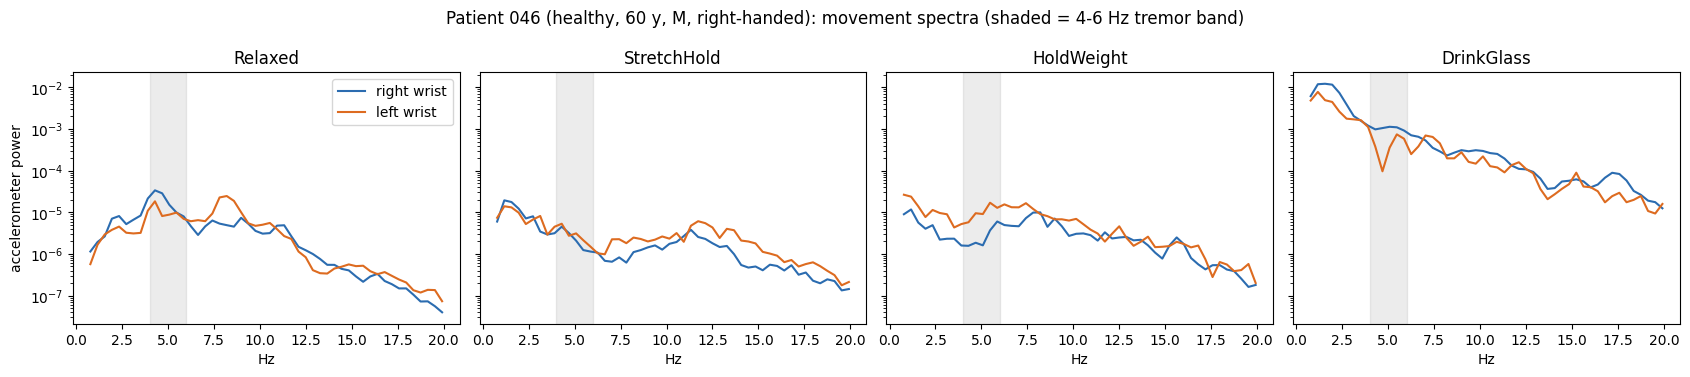

In [45]:
#This step creates a movememnt signature figure for the healthy participant
#Note that the figure itself is not used in the porposal, but the number and outcome are used as a baseline
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for a, task in zip(ax, ["Relaxed", "StretchHold", "HoldWeight", "DrinkGlass"]):
    for wrist, c in [("right", "#2b6cb0"), ("left", "#dd6b20")]:
        f, P = welch(np.vstack(segments[(task, wrist)])[:, :3], fs=FS, nperseg=256, axis=0)
        k = (f >= 0.5) & (f <= 20)
        a.semilogy(f[k], P.sum(axis=1)[k], color=c, label=f"{wrist} wrist")
    a.axvspan(4, 6, color="grey", alpha=0.15)
    a.set_title(task); a.set_xlabel("Hz")
ax[0].set_ylabel("accelerometer power"); ax[0].legend()
fig.suptitle("Patient 046 (healthy, 60 y, M, right-handed): movement spectra (shaded = 4-6 Hz tremor band)")
fig.tight_layout(); plt.savefig("pt46_signature.png", dpi=200); plt.show()

Parkinson's Disease

In [46]:
pt55_relr = load('055_Relaxed_RightWrist.txt')
pt55_rell = load('055_Relaxed_LeftWrist.txt')

pt55_strr = load('055_StretchHold_RightWrist.txt')
pt55_strl = load('055_StretchHold_LeftWrist.txt')

pt55_drr  = load('055_DrinkGlas_RightWrist.txt')
pt55_drl  = load('055_DrinkGlas_LeftWrist.txt')

pt55_holr = load('055_HoldWeight_RightWrist.txt')
pt55_holl = load('055_HoldWeight_LeftWrist.txt')

In [47]:
pt68_relr = load('068_Relaxed_RightWrist.txt')
pt68_rell = load('068_Relaxed_LeftWrist.txt')

pt68_strr = load('068_StretchHold_RightWrist.txt')
pt68_strl = load('068_StretchHold_LeftWrist.txt')

pt68_drr  = load('068_DrinkGlas_RightWrist.txt')
pt68_drl  = load('068_DrinkGlas_LeftWrist.txt')

pt68_holr = load('068_HoldWeight_RightWrist.txt')
pt68_holl = load('068_HoldWeight_LeftWrist.txt')

In [48]:
#This is taking the segments of the PD patients and creating a dictionary mapping their movement and dataframe
#a building their own movement signatures

suffix = {"relr": ("Relaxed", "right"), "rell": ("Relaxed", "left"),
          "strr": ("StretchHold", "right"), "strl": ("StretchHold", "left"),
          "holr": ("HoldWeight", "right"), "holl": ("HoldWeight", "left"),
          "drr": ("DrinkGlass", "right"), "drl": ("DrinkGlass", "left")}

def build_signature(pid):
    segs, rows = {}, {}
    for suf, key in suffix.items():
        df = globals()[f"pt{pid}_{suf}"]          # e.g. pt55_relr
        segs[key] = clean(df)
        per_seg = [{**sensor_features(s[:, :3], "acc"), **sensor_features(s[:, 3:], "gyr")} for s in segs[key]]
        rows[key] = pd.DataFrame(per_seg).mean()
    sig = pd.DataFrame(rows).T
    sig.index.names = ["task", "wrist"]
    return sig, segs


#This step creates tables including the tasks as rows and movement features as columns
sig55, segments55 = build_signature(55)
sig68, segments68 = build_signature(68)
print(sig55.shape, sig68.shape)    # expect (8, 12) each

(8, 12) (8, 12)


In [49]:
#This step looks at the deviation of each of these features relative to the healthy baseline, as a log10 difference
#It goes through each task and wrist dominance row at a time
band_cols = [f"{s}_bp_{b}" for s in ("acc", "gyr") for b in ("0.5-3", "4-6", "6-12")]
rms_cols = ["acc_rms", "gyr_rms"]
ent_cols = ["acc_spec_entropy", "gyr_spec_entropy"]

patients = {"Pt 55 (PD, 10 y)": sig55, "Pt 68 (PD, 4 y)": sig68}
diff = {name: s - signature for name, s in patients.items()}   # signed log10 difference vs baseline

#The results give 4 summary numbers showing mean deviation per frequency band, the amplitude difference, the difference in the 4-6 band frqeuncy and entropy difference
results = pd.DataFrame({
    name: {
        "deviation (mean |log10 diff|, bands)": d[band_cols].abs().mean(axis=1).mean(),
        "amplitude diff (mean log10 rms)": d[rms_cols].mean(axis=1).mean(),
        "tremor-band 4-6 Hz diff": d[["acc_bp_4-6", "gyr_bp_4-6"]].mean(axis=1).mean(),
        "entropy diff": d[ent_cols].mean(axis=1).mean(),
    } for name, d in diff.items()
}).round(2)
print(results)

# This step looks at a break down per task x wrist deviation
per_unit = pd.DataFrame({name: d[band_cols].abs().mean(axis=1) for name, d in diff.items()}).round(2)
print(per_unit)
per_unit.to_csv("deviation_per_task_wrist.csv"); results.to_csv("deviation_summary.csv")

                                      Pt 55 (PD, 10 y)  Pt 68 (PD, 4 y)
deviation (mean |log10 diff|, bands)              0.42             2.33
amplitude diff (mean log10 rms)                  -0.22             1.26
tremor-band 4-6 Hz diff                          -0.29             3.02
entropy diff                                      0.04            -0.19
                   Pt 55 (PD, 10 y)  Pt 68 (PD, 4 y)
task        wrist                                   
Relaxed     right              0.71             3.35
            left               0.75             3.08
StretchHold right              0.27             1.57
            left               0.08             1.88
HoldWeight  right              0.10             3.21
            left               0.34             2.22
DrinkGlass  right              0.89             1.92
            left               0.21             1.44


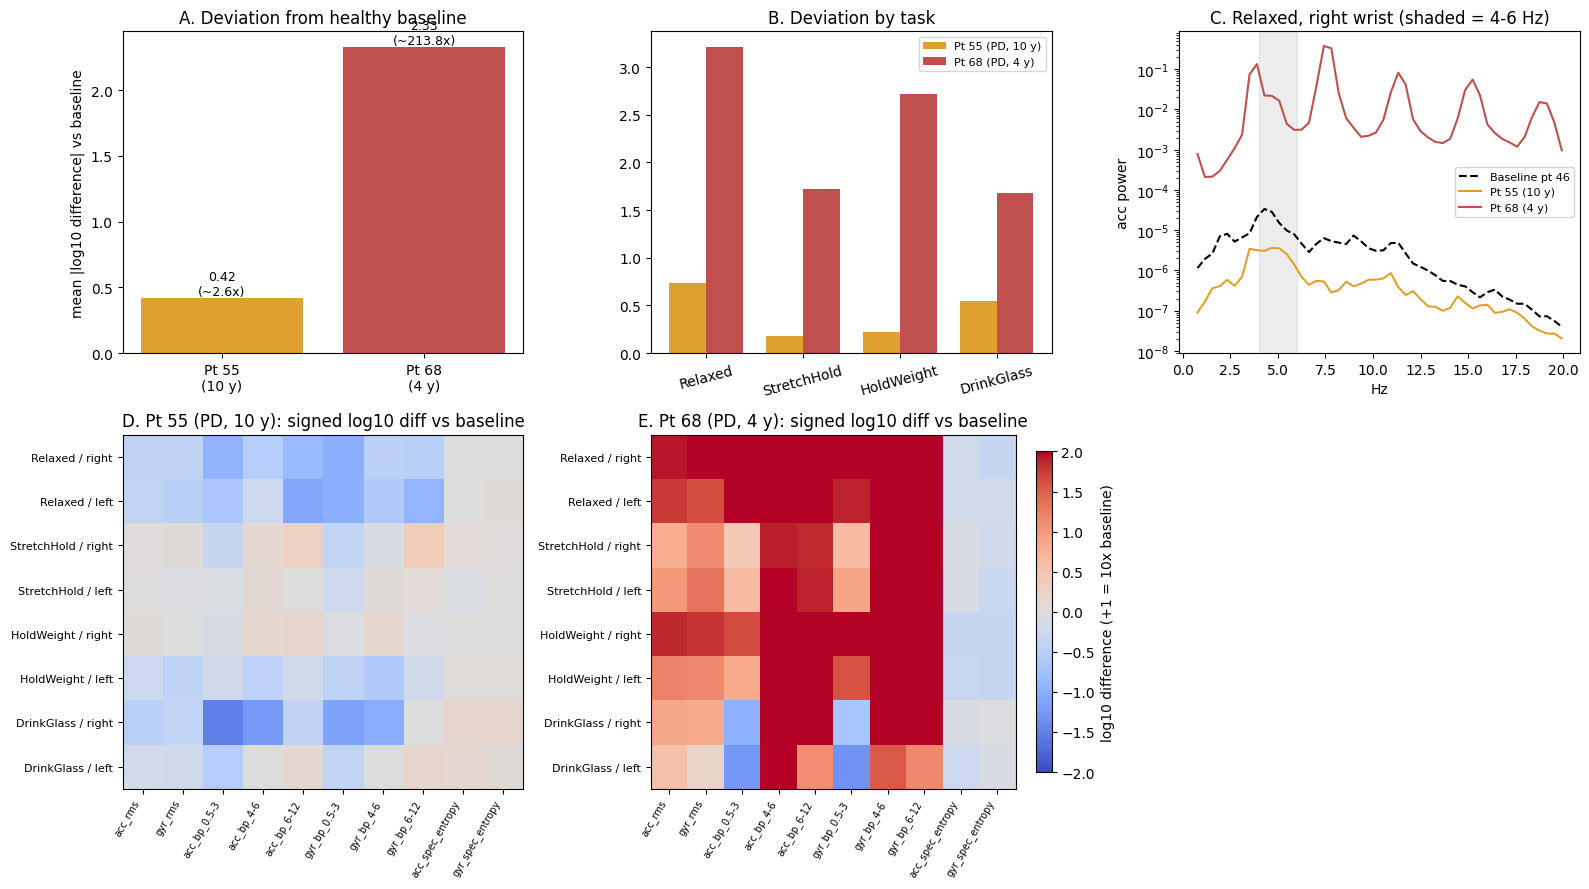

In [32]:
#This cell creates the overall figure representing the difference between the healthy and both PD patients
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
colors = ["#E0A030", "#C0504D"]

# A: Overall deviation using the mean deviation across bands
ax = fig.add_subplot(gs[0, 0])
vals = results.loc["deviation (mean |log10 diff|, bands)"]
ax.bar(["Pt 55\n(10 y)", "Pt 68\n(4 y)"], vals.values, color=colors)
for i, v in enumerate(vals.values):
    ax.text(i, v + 0.02, f"{v:.2f}\n(~{10**v:.1f}x)", ha="center", fontsize=9)
ax.set_ylabel("mean |log10 difference| vs baseline"); ax.set_title("A. Deviation from healthy baseline")

# B: This creates a chart showing deviation by task
ax = fig.add_subplot(gs[0, 1])
tasks = ["Relaxed", "StretchHold", "HoldWeight", "DrinkGlass"]
for i, (name, c) in enumerate(zip(diff, colors)):
    s = per_unit[name].groupby(level="task").mean().reindex(tasks)
    ax.bar(np.arange(4) + (i - 0.5) * 0.38, s.values, 0.38, color=c, label=name)
ax.set_xticks(range(4)); ax.set_xticklabels(tasks, rotation=15); ax.legend(fontsize=8)
ax.set_title("B. Deviation by task")

# C: relaxed task spectrum, right (dominant) wrist
ax = fig.add_subplot(gs[0, 2])
for label, segs, c, ls in [("Baseline pt 46", segments, "black", "--"),
                           ("Pt 55 (10 y)", segments55, colors[0], "-"),
                           ("Pt 68 (4 y)", segments68, colors[1], "-")]:
    f, P = welch(np.vstack(segs[("Relaxed", "right")])[:, :3], fs=FS, nperseg=256, axis=0)
    k = (f >= 0.5) & (f <= 20)
    ax.semilogy(f[k], P.sum(axis=1)[k], color=c, ls=ls, label=label)
ax.axvspan(4, 6, color="grey", alpha=0.15); ax.set_xlabel("Hz"); ax.set_ylabel("acc power")
ax.set_title("C. Relaxed, right wrist (shaded = 4-6 Hz)"); ax.legend(fontsize=8)

# D, E: signed difference heatmaps (red = patient higher than baseline)
cols_show = rms_cols + band_cols + ent_cols
for j, (name, d) in enumerate(diff.items()):
    ax = fig.add_subplot(gs[1, j])
    m = d[cols_show]
    im = ax.imshow(m.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(len(cols_show))); ax.set_xticklabels(cols_show, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(m))); ax.set_yticklabels([f"{t} / {w}" for t, w in m.index], fontsize=8)
    ax.set_title(f"{'DE'[j]}. {name}: signed log10 diff vs baseline")
    if j == 1:
        fig.colorbar(im, ax=ax, fraction=0.04, label="log10 difference (+1 = 10x baseline)")
fig.tight_layout(); plt.savefig("mini_model_results.png", dpi=200); plt.show()